# Faster, cheaper, still right? An evaluation of the 06/11 planning round

*Run on 8 November 2026 against the dev environment.*

We changed how every prompt is built. The system prompt now comes from a versioned **Prompt Registry**. Conversation memory moved out of it (**layout v2**) so providers can reuse their KV cache. Images of recent turns now travel **in place** in the history (the **hot window**). An **Artifact Resolver** decides which earlier design a question refers to. **Essay Mode** now folds its question analysis into the router's single auxiliary call.

Changes like these can quietly make answers worse, or fail to deliver the speed-up they promise. This notebook checks both.

### The story in four sentences
1. **Answers held up.** The QA golden set scores 94% with every case passing. All three QNX essays meet length, citation and coverage targets. The resolver gets all 33 reference cases right.
2. **The cache works where it was designed to.** The ~4k-token static system prompt is shared *across different conversations*. Right after `/c4` adds an artifact, the old layout (**v1**) loses its entire cache while **v2** keeps ~4,080 tokens.
3. **Gemini's cache has real limits.** Hits grow in ~2k-token steps and trail one turn behind, so short histories barely benefit. The hot window showed no measurable gain on a 5-turn chat.
4. **We caught a live incident.** Gemini returned 503s for about four minutes mid-run. Retries, the circuit breaker and fallback behaved as designed, and the incident exposed a **retired fallback model** in the default chain, now removed.

> **Setup.** Local harness pointed at **dev**: Neon dev branch, R2 `cter-dev`, Pinecone `cter-develop-uat`. Model: `gemini-3.1-flash-lite`. A temporary vault of 10 Week-01/02 lecture notes (195 KB) was deleted afterwards. Raw data: `evals/results/` and `evals/reports/data/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import report_lib as R
R.style()
pd.set_option('display.max_colwidth', 60)
qa, qa_summary = R.qa_results()
essay, essay_summary = R.essay_results()
refs = R.reference_results()
runs = R.cache_runs()
incident = R.incident()

## 1. The scoreboard

In [2]:
plain = refs[~refs['ambiguousExpected']]
amb = refs[refs['ambiguousExpected']]
judge_cols = [c for c in essay.columns if c.startswith('judge_')]
kpi = pd.DataFrame([
    ('QA golden set (rules)', f"{R.pct(qa_summary['meanScore'])} · pass {R.pct(qa_summary['passRate'])} · judge {R.pct(qa['judge'].mean())}", f"{len(qa)} cases"),
    ('Essay Mode (rules)', f"{R.pct(essay_summary['meanScore'])} · judge {essay[judge_cols].mean().mean():.1f}/5", f"{len(essay)} cases"),
    ('Artifact resolution (offline)', f"{R.pct(plain['ok'].mean())} · ambiguous {R.pct(amb['ok'].mean())}", f"{len(refs)} cases"),
    ('Cache share, new conversations (median)', f"{R.pct((qa['cached'] / qa['input']).median())}", 'each QA question is a fresh conversation'),
    ('QA answer time', f"p50 {qa['total_s'].median():.1f}s · max {qa['total_s'].max():.1f}s", f"{len(qa)} cases"),
], columns=['Area', 'Result', 'Sample'])
kpi.style.hide(axis='index')

Area,Result,Sample
QA golden set (rules),94% · pass 100% · judge 99%,8 cases
Essay Mode (rules),100% · judge 5.0/5,3 cases
Artifact resolution (offline),100% · ambiguous 100%,33 cases
"Cache share, new conversations (median)",75%,each QA question is a fresh conversation
QA answer time,p50 4.4s · max 6.9s,8 cases


## 2. Did answer quality survive the refactor?

Each golden question lists the points a good answer must contain. The **rule score** is the share of points present, with penalties for a leftover References section or forbidden notation. The **judge** is the same model grading the answer from 0 to 10.

The first thing worth knowing is how much a *single* run can move. We ran the set twice with the same prompt and model:

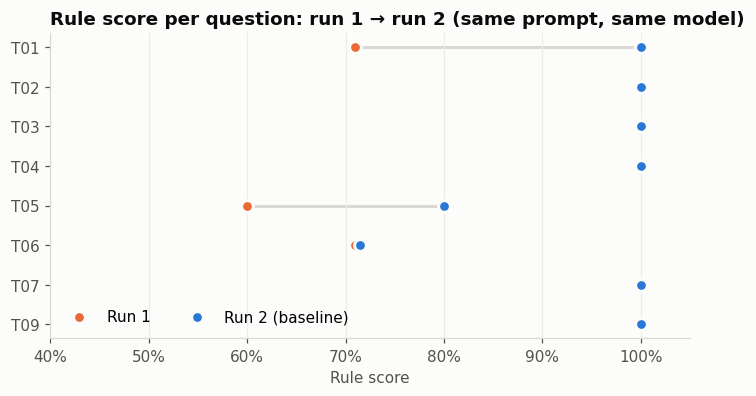

In [3]:
fig = R.plot_qa_runs(qa, 'en'); fig.axes[0].set_title('Rule score per question: run 1 → run 2 (same prompt, same model)'); plt.show()

Two of eight questions moved by 20–30 points between identical runs: T01 71%→100% and T05 60%→80%. **That is the noise floor.** A prompt change that shifts one question by 20 points proves nothing. Compare means across repeated runs. Run 2 is now stored as `evals/results/baseline.json`.

In [4]:
qa[['id', 'score', 'judge', 'missing', 'total_s']].rename(columns={'score': 'rule', 'missing': 'missing points', 'total_s': 'seconds'})

,id,rule,judge,missing points,seconds
0,T01,1.000000,1.0,,5.997
1,T02,1.000000,1.0,,4.983
2,T03,1.000000,1.0,,6.870
3,T04,1.000000,1.0,,6.722
4,T05,0.800000,0.9,*n,3.140
5,T06,0.714286,1.0,"uname, kill",3.247
6,T07,1.000000,1.0,,3.814
7,T09,1.000000,1.0,,3.294


What the answers miss are enumerations (`uname`, `kill` in T06; the `*n` notation in T05), not wrong concepts. The judge scores 90–100%, but a model grading itself is lenient; see the limitations at the end.

## 3. Where does the time go?

Every answer is retrieval (embedding, Pinecone, BM25) followed by generation.

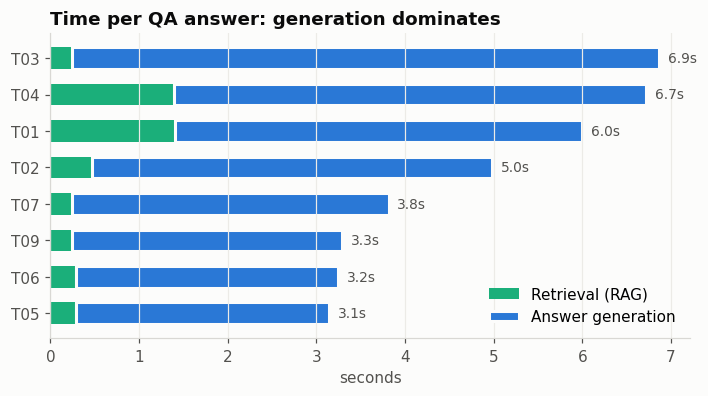

In [5]:
fig = R.plot_qa_latency(qa, 'en'); fig.axes[0].set_title('Time per QA answer: generation dominates'); plt.show()

Generation dominates. Retrieval costs ~1.4 s while the embedder is cold and ~0.25 s once warm. Every answer finished in **under 7 seconds**, far inside the 90 s chat deadline. KV caching attacks the generation side, specifically the prefill of the prompt.

## 4. The cache across users

If layout v2 does its job, the static system prompt (layer ①) is **byte-identical for every request**, so a brand-new conversation should already find it in Gemini's cache. Each QA question was sent as a new conversation:

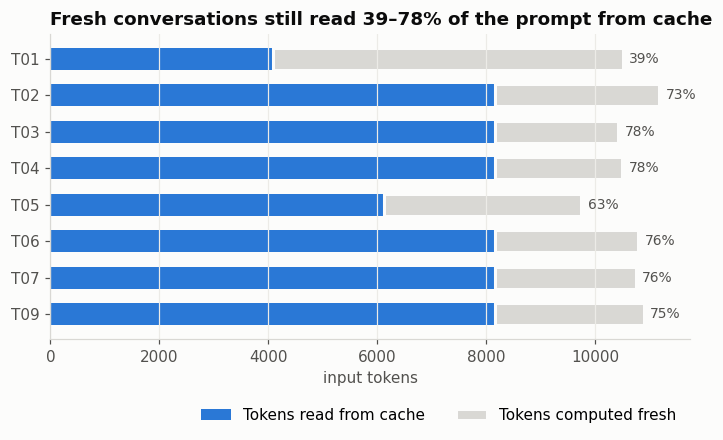

In [6]:
fig = R.plot_cross_conversation_cache(qa, 'en'); fig.axes[0].set_title('Fresh conversations still read 39–78% of the prompt from cache'); plt.show()

Six of eight questions read **~8,166 tokens (~75% of the prompt)** from cache: more than the ~4k-token static layer alone, so some other part of these requests is identical too (we have not pinned down which). T01, the first request after start-up, found a cold cache. T05 landed one ~2k-token block lower; Gemini's implicit caching is best-effort.

**Why it matters:** with many students asking questions, every new request starts with a warm prefix, which helps time-to-first-token from the very first turn.

## 5. The cache turn by turn: v1 vs v2, with and without the hot window

`npm run eval:cache` replays the same script under three configurations, restarting the harness in between:
- The **c4** script: chat, then `/c4` draws a diagram, then three follow-ups about it.
- The **long** script: six detailed answers.

| Config | `PROMPT_CACHE_LAYOUT` | `CONTEXT_HOT_WINDOW_TURNS` |
|---|---|---|
| v2-k2 (new default) | v2 | 2 |
| v2-k0 | v2 | 0 |
| v1-k0 (rollback) | v1 | 0 |

In [7]:
rows = []
for run in runs:
    for _, t in run.turns.iterrows():
        rows.append({'config': run.config, 'run': run.label, 'scenario': run.scenario, 'turn': t['turn'], 'kind': t['kind'],
                     'ok': t['ok'], 'input': t['inputTokens'], 'cached': t['cachedTokens'],
                     'ttft_s': None if pd.isna(t['ttftMs']) else round(t['ttftMs'] / 1000, 2)})
cache = pd.DataFrame(rows)
pivot = cache[(cache['scenario'] == 'c4') & cache['ok'] & (cache['kind'] == 'chat')].pivot_table(index='turn', columns='run', values='cached', aggfunc='first')
pivot

run,v1-k0,v2-k0,v2-k2,v2-k2-r2
turn,,,,
1,0.0,4083.0,4083.0,8166.0
3,0.0,4080.0,4079.0,4079.0
4,4075.0,4076.0,4076.0,4076.0
5,4074.0,4074.0,4074.0,4074.0


### The moment that matters: turn 3

Turn 3 is the first question after `/c4` created new artifacts.
- **v1 reads 0 cached tokens.** The artifact registry lives inside its system prompt, so the new artifact rewrote the system prompt and invalidated everything after it.
- **v2 reads ~4,080.** The registry lives at the tail, so layer ① did not change.

This is exactly the failure note 18 predicted, and the fix works.

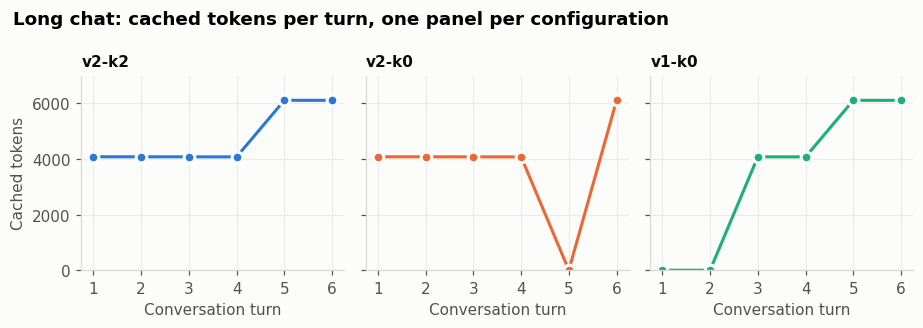

In [8]:
fig = R.plot_cache_turns(runs, 'long', 'en'); fig.suptitle('Long chat: cached tokens per turn, one panel per configuration', x=0.02, ha='left', fontweight='bold'); fig.tight_layout(); plt.show()

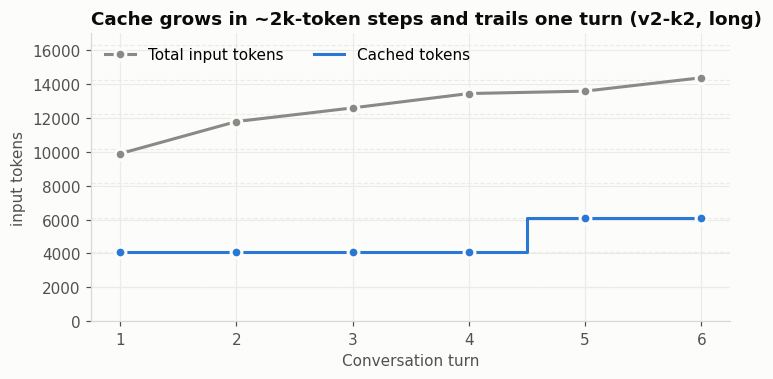

In [9]:
long_run = [r for r in runs if r.label == 'v2-k2-long'][0]
fig = R.plot_cache_blocks(long_run, 'en'); fig.axes[0].set_title('Cache grows in ~2k-token steps and trails one turn (v2-k2, long)'); plt.show()

### Why the history barely shows up in the cache
1. **It trails by a turn.** Request *n* ends with question *n* plus its retrieved context. In request *n+1*, turn *n* appears as plain text without that context. The longest prefix shared with the previous request therefore ends at turn *n−1*.
2. **It moves in ~2k-token steps.** Gemini reports cached tokens in multiples of ~2,037. The history has to grow by about 2k tokens to earn the next step, which in the long script first happens at turn 5 (6,114). v2-k0 missed entirely at turn 5 (0) and hit again at turn 6: Gemini's cache is best-effort.
3. **Hot window K=2 vs K=0: no visible difference.** A rendered C4 PNG is smaller than one step, and the window slides every turn. The benefit should appear with large or multiple images, such as screenshot-heavy exam prompts, and that needs its own measurement.
4. **The v1 turns 1–2 at zero are partly a cold start.** They were the first v1 requests after a restart, and in production other users would warm that prefix. The *real* v1/v2 difference is the turn right after a new artifact.

## 6. Essay Mode: one auxiliary call instead of two

An essay question carries points, which become a target length (points × 175 words). The checks are: length within ±25%, every `[c:id]` citation pointing at a retrieved chunk, all aspects covered, and the expected week cited.

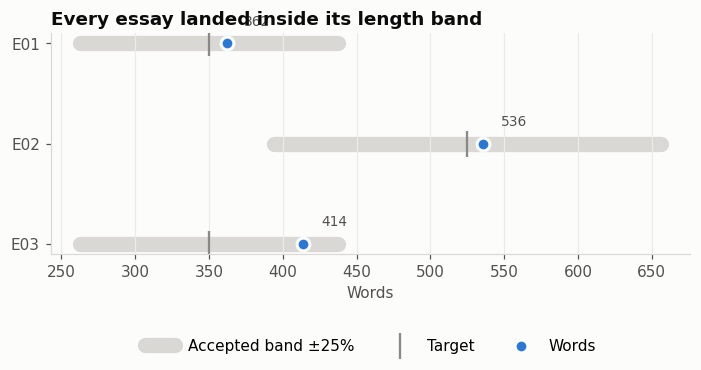

In [10]:
fig = R.plot_essay_length(essay, 'en'); fig.axes[0].set_title('Every essay landed inside its length band'); plt.show()

In [11]:
essay[['id', 'score', 'words', 'target', 'citations_ok', 'coverage', 'llm_calls', 'total_s', 'input', 'cached']]

,id,score,words,target,citations_ok,coverage,llm_calls,total_s,input,cached
0,E01,1,362,350,True,1,2,9.738,11781,0
1,E02,1,536,525,True,1,2,10.133,15334,0
2,E03,1,414,350,True,1,2,10.680,13823,0


- **`llm_calls = 2`**: one shared auxiliary call (routing *and* question analysis, previously two separate calls) plus the writing call. The merge did what it was meant to.
- **The judge gave 5/5 on every criterion.** That is a ceiling effect, not a verdict: a model grading its own output cannot separate good from great. Use a stronger judge next time (`EVAL_JUDGE_MODEL`).
- ⚠️ **Finding: essays read 0 cached tokens** despite 12–15k-token prompts. The essay prompt (rubric + writer skill) has no stable prefix the way chat does. This is the next caching opportunity.

## 7. Does the resolver pick the right artifact?

33 offline cases over synthetic conversations: one design, two systems, version chains, different phrasings, ambiguous and negative questions. They run on rules alone and cost zero tokens.

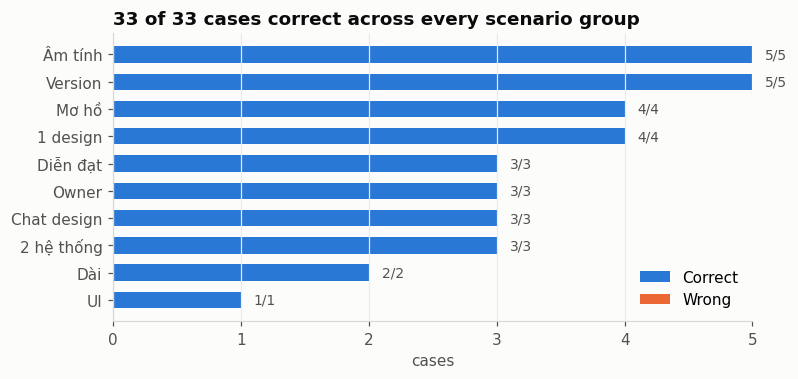

In [12]:
fig = R.plot_reference_groups(refs, 'en'); fig.axes[0].set_title('33 of 33 cases correct across every scenario group'); plt.show()

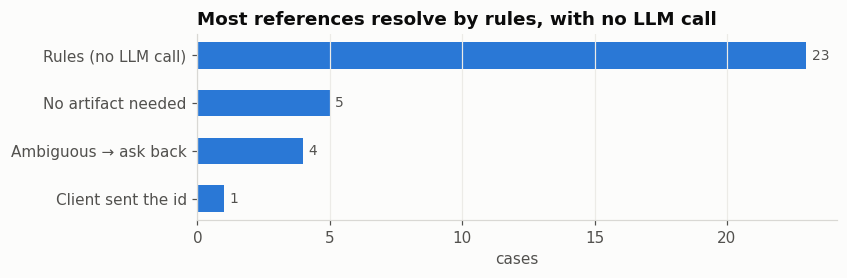

In [13]:
fig = R.plot_reference_sources(refs, 'en'); fig.axes[0].set_title('Most references resolve by rules, with no LLM call'); plt.show()

> ⚠️ The rules were tuned **on this very set**, so 100% is an upper bound. Real questions will score lower. Watch `resolved_refs` in the monitoring UI (Chats page) to see how they behave in practice.

## 8. An unplanned stress test: Gemini goes down

Between 07:51 and 07:55, Gemini answered **503 "high demand"**. That gave us live evidence for the resilience work of note 07:

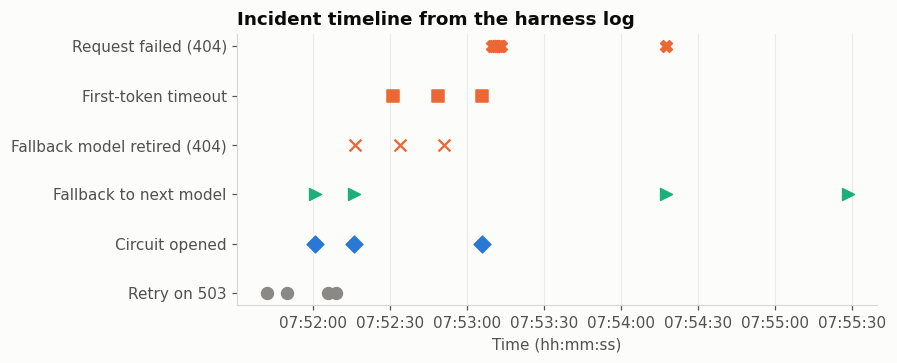

In [14]:
fig = R.plot_incident(incident, 'en'); fig.axes[0].set_title('Incident timeline from the harness log'); plt.show()

- **Retries are bounded.** Two retries on 503 (`MAX_RETRY_COUNT=2`), then the **circuit opens** for 120 s and the next model is tried. With the old setting of 12 retries, the same outage would have held requests for more than five minutes.
- **The fallback chain had a dead link.** `gemini-2.5-flash-lite` has been retired by Google (404), so every request wasted one attempt on it. It is **removed from the code default and `.env.example`**. `MODEL_FALLBACK_GEMINI` in the dev `.env` and on Render still needs a manual edit.
- **The last resort stalled too.** OpenRouter's `gemini-3.5-flash` produced no first token within 15 s. When a whole provider is saturated, requests still fail, but they **fail fast** instead of hanging.

## 9. What we conclude, and what we do next

| # | Finding | Action |
|---|---|---|
| 1 | QA, Essay and resolver quality hold | Baseline saved (`evals/results/baseline.json`, mean 94%); prompt changes must not drop below it |
| 2 | v2 keeps the cache when artifacts change; v1 does not | Keep `PROMPT_CACHE_LAYOUT=v2` |
| 3 | Short histories barely cache (2k steps, one-turn lag) | The main win is the shared layer ①; don't promise history savings for short chats |
| 4 | Hot window shows no measurable gain yet | Keep K=2, re-measure with image-heavy prompts; set `CONTEXT_HOT_WINDOW_TURNS=0` if it only costs quota |
| 5 | Essays get no cache | Next optimisation: a stable static prefix for the essay prompt |
| 6 | Retired model in the fallback chain | Fix `MODEL_FALLBACK_GEMINI` in dev `.env` and on Render |

### Limitations
- **Small samples.** 8 QA, 3 essay and 33 resolver cases; each cache configuration ran once or twice.
- **One model.** Only Gemini flash-lite was measured, and it is also its own judge.
- **Partial vault.** Only the Week-01/02 notes were loaded, so the Software Testing and Usability essays were not measured.
- **Noisy cache.** Gemini's implicit cache is best-effort, and part of the run overlapped a provider incident.

### Reproduce
Run the eval commands in `planning/planning-06112026/handoff/05-system-prompt-guide.md` §5 against a dev harness, then *Run All*.